In [2]:
import pandas as pd

# Read existing CSV dataset
df = pd.read_csv("diabetes.csv")

# Display dataset
print(df.head())

print("Dataset shape:", df.shape)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  
Dataset shape: (768, 9)


In [3]:

print("\nColumns:", list(df.columns))
print("\nFirst 5 rows:")
print(df.head())


Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'Pedigree', 'Age', 'Outcome']

First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  


In [4]:
import numpy as np

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Separate target
y = pd.to_numeric(df["Outcome"]).astype(int)

# Separate features
X = df.drop(columns=["Outcome"])

# Remove ID columns if present
X = X.drop(
    columns=[c for c in X.columns
             if c.lower() in ["id", "patientid"]],
    errors="ignore"
)

# Convert features to numeric
X = X.apply(pd.to_numeric)

# Replace infinity with missing values
X = X.replace([np.inf, -np.inf], np.nan)

print("Features:", X.shape)
print("\nClass counts:")
print(y.value_counts())

Features: (768, 8)

Class counts:
Outcome
0    500
1    268
Name: count, dtype: int64


In [5]:
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for col in zero_columns:
    if col in X.columns:
        X.loc[X[col] == 0, col] = np.nan

print("Missing values after treating zeros:")
print(X.isnull().sum())

Missing values after treating zeros:
Pregnancies        0
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
Pedigree           0
Age                0
dtype: int64


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 614
Testing rows: 154


In [7]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(
        n_neighbors=5,
        metric="euclidean"
    ))
])

model.fit(X_train, y_train)

prediction = model.predict(X_test)

print("KNN model trained successfully!")

KNN model trained successfully!


In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test, prediction)
error_rate = 1 - accuracy

precision = precision_score(
    y_test, prediction,
    pos_label=1,
    zero_division=0
)

recall = recall_score(
    y_test, prediction,
    pos_label=1,
    zero_division=0
)

f1 = f1_score(
    y_test, prediction,
    pos_label=1,
    zero_division=0
)

print("Accuracy :", accuracy)
print("Error Rate:", error_rate)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.7532467532467533
Error Rate: 0.24675324675324672
Precision: 0.66
Recall   : 0.6111111111111112
F1 Score : 0.6346153846153846


In [9]:
cm = confusion_matrix(
    y_test,
    prediction,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

print("\nConfusion Matrix:")
print("                 Predicted 0   Predicted 1")
print(f"Actual 0 (no)    {tn:11d}   {fp:11d}")
print(f"Actual 1 (yes)   {fn:11d}   {tp:11d}")


Confusion Matrix:
                 Predicted 0   Predicted 1
Actual 0 (no)             83            17
Actual 1 (yes)            21            33


In [10]:
print(
    classification_report(
        y_test,
        prediction,
        labels=[0, 1],
        target_names=["Outcome 0", "Outcome 1"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

   Outcome 0       0.80      0.83      0.81       100
   Outcome 1       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



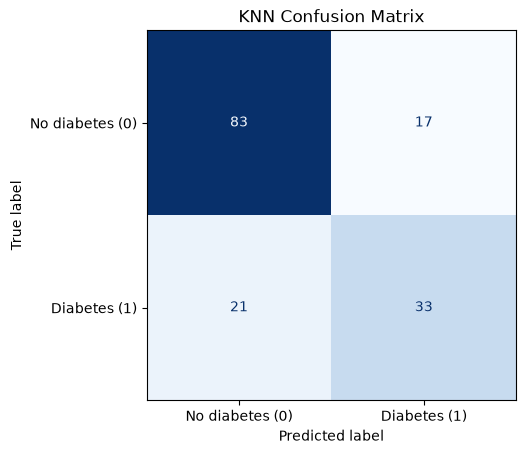

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay(
    cm,
    display_labels=["No diabetes (0)", "Diabetes (1)"]
).plot(
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

plt.title("KNN Confusion Matrix")
plt.show()